In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec

import sys
import testis_model as tm

from analysis import *

In [2]:
colors = tm.visualize.default_colors

In [3]:
model_simulations_path = os.path.join('..', 'model_simulations')

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)
    print("Added to path:", model_simulations_path)
    
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('full_pipeline', directory = scenarios_directory)

fish_id = 1
fish = fish_data[exp_scenario, fish_id, 0]

Added to path: ../model_simulations


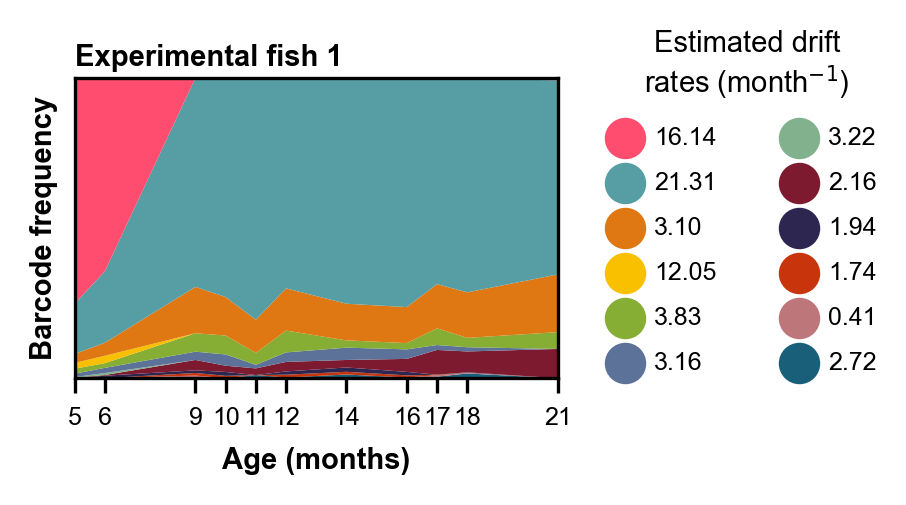

In [16]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig = plt.figure(figsize=(3.2, 1.3), dpi=300)

gs = GridSpec(
    1, 2,
    width_ratios=[1, 0.4],
    wspace=0.2
)

ax = fig.add_subplot(gs[0, 0])   # your main plot
ax2 = fig.add_subplot(gs[0, 1])

tm.visualize.plot(fish, ax=ax)
ax.set_yticks([])
ax.set_xlabel('Time (months)')
ax.set_title('Experimental fish 1', fontweight = 'bold', loc = 'left', pad = 3)
ax.set_ylabel('Barcode frequency', fontweight = 'bold')
ax.set_xlabel('Age (months)', fontweight = 'bold')

# Add the point to the right of the plot
df2 = df.query('scenario == @exp_scenario and fish == 1')
for i, row in df2.iterrows():
    clone, r = row['clone'], row['r_opt']

    a = 0.8
    b = 4/(2*a-1)
    if clone < 6:
        x = 0
        y = a - clone / b
    else:
        x = 0.9
        y = a - (clone - 6) / b
        
    ax2.scatter(x, y, transform=ax2.transAxes, color=colors[clone], s=80, zorder=999, clip_on = False)
    ax2.text(x + 0.15, y, f'{r:.2f}', transform = ax2.transAxes, va = 'center', size=6)

ax2.text(0.63, 0.95, 'Estimated drift\nrates (month$^{-1}$)', transform = ax2.transAxes, ha = 'center')

ax2.axis('off')

# plt.tight_layout()

filepath = os.path.join('images', 'fig3', 'inference_strategy.svg')
plt.savefig(filepath, bbox_inches='tight', pad_inches=0)